# 02. Исследование аномалий в дашборде

**Формат:** учебный проект по анализу данных и отладке ETL  
**Инструменты:** Python, pandas, SQL, SQLite, Dash, Plotly, Jupyter Notebook

В Notebook собраны мои проверки: от первых подозрений по графикам до сравнения исходной и исправленной версий проекта.

## 1. Постановка задачи

После изменений в обработке логов интернет-магазина на дашборде появились странные значения. Данные хранятся в SQLite, затем Python-скрипты рассчитывают метрики для графиков.

**Цель:** найти причины аномалий и исправить расчёты, не меняя исходную базу данных.

**План:** сначала посмотреть на графики, затем проверить исходные данные и витрины, исправить найденные ошибки в копии проекта и сравнить показатели до и после.

## 2. Что насторожило на дашборде

При просмотре графиков заметила несколько особенностей:

- В начале августа пополнения резко падают до нуля, хотя списания продолжаются.
- Retention D+30 в конце графика также становится нулевым.
- Периоды 180 и 365 дней выглядят почти одинаково.

Пока это **наблюдения, а не доказанные ошибки**. Начну с пополнений: их можно проверить непосредственно в таблицах.

## 3. Ошибка в учёте пополнений

### 3.1. Сравнение исходных транзакций и витрины

Сначала найду локальные SQLite-базы. Для проверок открываю их **только на чтение**, чтобы не менять исходные данные.

In [1]:

import sqlite3
import pandas as pd
from pathlib import Path

# Находим папку проекта
root = Path.cwd()

if root.name == "02-dashboard-debugging":
    project = root
else:
    project = root / "02-dashboard-debugging"

db_dir = project / "originals" / "37889-solution-main" / "database"

print("Папка с базами:", db_dir)
print("База найдена:", (db_dir / "database.db").is_file())


Папка с базами: /Users/lady/Downloads/yandex-analytics-portfolio/02-dashboard-debugging/originals/37889-solution-main/database
База найдена: True


База найдена. Теперь посмотрю, какие операции и суммы записаны за последние дни доступного периода.

In [2]:

raw_db = (db_dir / "database.db").resolve()

with sqlite3.connect(f"file:{raw_db}?mode=ro", uri=True) as conn:
    raw_daily = pd.read_sql_query("""
        SELECT
            date,
            type,
            COUNT(*) AS operations,
            SUM(amount) AS total_amount
        FROM transactions
        WHERE date BETWEEN '2026-07-29' AND '2026-08-04'
        GROUP BY date, type
        ORDER BY date, type
    """, conn)

raw_daily


,date,type,operations,total_amount
0,2026-07-29,debit,172,123845
1,2026-07-29,topup,453,418243
2,2026-07-30,debit,198,168803
3,2026-07-30,topup,452,410925
4,2026-07-31,debit,173,134472
5,2026-07-31,topup,454,422465
6,2026-08-01,debit,189,146439
7,2026-08-01,topup,458,409656
8,2026-08-02,debit,187,143414
9,2026-08-02,top-up,457,416062


**Наблюдение.** До 2 августа пополнения записаны как `topup`, а начиная со 2 августа — как `top-up`. Суммы при этом остаются ненулевыми. Проверю, отражены ли они в финансовой витрине.

In [3]:

# Проверяем суммы пополнений в готовой витрине
vitrine_db = (db_dir / "vitrine.db").resolve()

with sqlite3.connect(f"file:{vitrine_db}?mode=ro", uri=True) as conn:
    vitrine_daily = pd.read_sql_query("""
        SELECT
            SUBSTR(date, 1, 10) AS date,
            topup_sum_pro + topup_sum_lite AS topup_sum,
            debit_sum_pro + debit_sum_lite AS debit_sum
        FROM financial_daily
        WHERE date >= '2026-08-01'
        ORDER BY date
    """, conn)

vitrine_daily


,date,topup_sum,debit_sum
0,2026-08-01,409656,146439
1,2026-08-02,0,143414
2,2026-08-03,0,144208
3,2026-08-04,0,176113


**Результат.** В `financial_daily` за 2–4 августа пополнения равны нулю, хотя в `transactions` они есть. Значит, проблема возникла на этапе расчёта витрины.

В `financial_dayly.py` обнаружила фильтр только по `topup`. Он не учитывает новое название `top-up`.

### 3.2. Проверка исправленного финансового расчёта

В рабочей копии `financial_dayly.py` заменила фильтр на `.isin(['topup', 'top-up'])` в двух функциях. Проверю пересчёт за 1–4 августа, пока без записи в базу.

In [4]:

import runpy

# Загружаем исправленную функцию из рабочей копии
script = project / "workbench" / "financial_dayly.py"
financial = runpy.run_path(str(script))

# Читаем операции за последние четыре дня
with sqlite3.connect(f"file:{raw_db}?mode=ro", uri=True) as conn:
    transactions_check = pd.read_sql_query("""
        SELECT
            t.date,
            t.client_id,
            t.type,
            t.service,
            t.amount,
            c.subscription_type
        FROM transactions AS t
        LEFT JOIN clients AS c
            ON t.client_id = c.client_id
        WHERE t.date BETWEEN '2026-08-01' AND '2026-08-04'
    """, conn)

transactions_check["date"] = pd.to_datetime(
    transactions_check["date"]
)

# Пересчитываем финансовые показатели в памяти
fixed_daily = financial["create_financial_daily"](
    transactions_check
)

fixed_daily["topup_sum"] = (
    fixed_daily["topup_sum_pro"]
    + fixed_daily["topup_sum_lite"]
)

fixed_daily[["date", "topup_sum"]]


,date,topup_sum
0,2026-08-01,409656
1,2026-08-02,416062
2,2026-08-03,415405
3,2026-08-04,419074


**Результат.** За 2–4 августа снова получаются ненулевые суммы. Они совпадают с суммами в исходных транзакциях; 1 августа значение не изменилось.

### 3.3. Поиск похожих фильтров

Одна операция может влиять на несколько метрик. Проверю остальные Python-скрипты на такое же строгое сравнение с `topup`.

In [7]:

# Ищем использование старого названия операции
vitrine_dir = project / "originals" / "37889-solution-main" / "vitrine"

for path in sorted(vitrine_dir.glob("*.py")):
    lines = path.read_text(encoding="utf-8").splitlines()

    for number, line in enumerate(lines, 1):
        if "['type'] == 'topup'" in line:
            print(f"{path.name}, строка {number}")
            print(line.strip())
            print()


cohort_dau_dayly.py, строка 92
topups_b = transactions_b[transactions_b['type'] == 'topup']

financial_dayly.py, строка 66
topups = seg_txns[seg_txns['type'] == 'topup']

financial_dayly.py, строка 129
topups = seg_txns[seg_txns['type'] == 'topup']

funnel_dayly.py, строка 91
active_topups = transactions_b[transactions_b['type'] == 'topup']



Нашла четыре вхождения старого фильтра в трёх файлах: `financial_dayly.py`, `cohort_dau_dayly.py`, `funnel_dayly.py`.

Изменила их в папке `workbench`. Ниже проверяю, что все четыре замены действительно сохранены.

In [8]:

# Проверяем исправления в рабочих копиях
workbench = project / "workbench"

expected = {
    "financial_dayly.py": 2,
    "cohort_dau_dayly.py": 1,
    "funnel_dayly.py": 1
}

old_filter = "['type'] == 'topup'"
new_filter = "['type'].isin(['topup', 'top-up'])"

for filename, expected_count in expected.items():
    path = workbench / filename

    if not path.exists():
        print(f"Файл не найден: {filename}")
        continue

    code = path.read_text(encoding="utf-8")

    fixed = code.count(new_filter)
    old = code.count(old_filter)

    print(f"{filename}: исправлено {fixed}/{expected_count}, старых условий {old}")


financial_dayly.py: исправлено 2/2, старых условий 0
cohort_dau_dayly.py: исправлено 1/1, старых условий 0
funnel_dayly.py: исправлено 1/1, старых условий 0


**Результат.** Все четыре замены найдены, старых условий в этих трёх рабочих файлах больше нет. Это проверка кода; влияние на сами метрики проверю отдельно.

### 3.4. Сколько пользователей терял старый фильтр?

Сравню количество уникальных клиентов с пополнениями по старому и новому условиям. Для этого использую `groupby()` и `nunique()`.

In [9]:

# Старый фильтр
old = transactions_check[
    transactions_check["type"] == "topup"
]

# Исправленный фильтр
new = transactions_check[
    transactions_check["type"].isin(["topup", "top-up"])
]

# Считаем уникальных клиентов по дням
old_users = old.groupby("date")["client_id"].nunique()
new_users = new.groupby("date")["client_id"].nunique()

# Сравниваем результаты
comparison = pd.DataFrame({
    "До исправления": old_users,
    "После исправления": new_users
}).fillna(0).astype(int)

comparison["Разница"] = (
    comparison["После исправления"]
    - comparison["До исправления"]
)

comparison


,До исправления,После исправления,Разница
date,,,
2026-08-01,458,458,0
2026-08-02,0,457,457
2026-08-03,0,459,459
2026-08-04,0,459,459


**Результат.** Старый фильтр показывал ноль пользователей с пополнениями за 2–4 августа. Новый учитывает соответственно **457, 459 и 459** пользователей. Эти значения относятся к каждому отдельному дню, а не ко всем уникальным клиентам за три дня.

Теперь посмотрю разбивку по тарифам `lite` и `pro`: ошибка могла затронуть оба сегмента.

In [10]:

# Учитываем оба названия пополнений
topups = transactions_check[
    transactions_check["type"].isin(["topup", "top-up"])
]

# Считаем уникальных клиентов по тарифам и датам
users_by_segment = (
    topups.groupby(["date", "subscription_type"])["client_id"]
    .nunique()
    .unstack(fill_value=0)
)

# Добавляем общий итог
users_by_segment["Всего"] = users_by_segment.sum(axis=1)

users_by_segment


subscription_type,lite,pro,Всего
date,,,
2026-08-01,322,136,458
2026-08-02,321,136,457
2026-08-03,337,122,459
2026-08-04,319,140,459


**Результат.** Пополнения есть у пользователей обоих тарифов. Например, 2 августа — 321 клиент `lite` и 136 клиентов `pro`. Дальше сверю эти числа с исходной витриной активности.

In [11]:

# Читаем сохранённые показатели из витрины
vitrine_db = (db_dir / "vitrine.db").resolve()

with sqlite3.connect(f"file:{vitrine_db}?mode=ro", uri=True) as conn:
    before = pd.read_sql_query("""
        SELECT
            SUBSTR(date, 1, 10) AS date,
            monetized_users_lite AS lite_before,
            monetized_users_pro AS pro_before
        FROM cohort_dau
        WHERE SUBSTR(date, 1, 10)
              BETWEEN '2026-08-01' AND '2026-08-04'
        ORDER BY date
    """, conn)

# Берём результат нашего исправленного фильтра
after = users_by_segment[["lite", "pro"]].reset_index()

after["date"] = pd.to_datetime(after["date"]).dt.strftime("%Y-%m-%d")

after = after.rename(columns={
    "lite": "lite_after",
    "pro": "pro_after"
})

# Объединяем результаты для сравнения
comparison_cohort = before.merge(after, on="date")

comparison_cohort


,date,lite_before,pro_before,lite_after,pro_after
0,2026-08-01,322,136,322,136
1,2026-08-02,0,0,321,136
2,2026-08-03,0,0,337,122
3,2026-08-04,0,0,319,140


**Результат.** В сохранённой витрине показатели с 2 августа равны нулю для обоих тарифов. Независимый расчёт по транзакциям возвращает ненулевые значения.

Проверю не только отдельный фильтр, но и исправленную функцию `create_cohort_dau()` из рабочей копии скрипта. В этом эксперименте сравниваю **пользователей с пополнениями**, а не весь расчёт удержания.

In [12]:

import runpy

# Загружаем исправленную функцию
script = project / "workbench" / "cohort_dau_dayly.py"
cohort = runpy.run_path(str(script))

# Читаем данные без изменения базы
with sqlite3.connect(f"file:{raw_db}?mode=ro", uri=True) as conn:
    clients = pd.read_sql_query(
        "SELECT * FROM clients", conn
    )

    events = pd.read_sql_query("""
        SELECT * FROM events
        WHERE SUBSTR(date, 1, 10)
        BETWEEN '2026-08-01' AND '2026-08-04'
    """, conn)

    transactions = pd.read_sql_query("""
        SELECT * FROM transactions
        WHERE SUBSTR(date, 1, 10)
        BETWEEN '2026-08-01' AND '2026-08-04'
    """, conn)

# Преобразуем даты
clients["registration_date"] = pd.to_datetime(
    clients["registration_date"]
)
events["date"] = pd.to_datetime(events["date"])
transactions["date"] = pd.to_datetime(transactions["date"])

# Запускаем исправленный расчёт
fixed_cohort = cohort["create_cohort_dau"](
    clients, events, transactions
)

# Смотрим только проверяемые показатели
fixed_cohort["date"] = fixed_cohort["date"].dt.strftime("%Y-%m-%d")

result = fixed_cohort.loc[
    fixed_cohort["date"].between("2026-08-01", "2026-08-04"),
    ["date", "monetized_users_lite", "monetized_users_pro"]
]

result


,date,monetized_users_lite,monetized_users_pro
178,2026-08-01,322,136
179,2026-08-02,321,136
180,2026-08-03,337,122
181,2026-08-04,319,140


**Результат.** За 1–4 августа исправленная функция возвращает те же значения по `lite` и `pro`, что и независимый подсчёт. Для показателя пользователей с пополнениями исправление подтверждено.

### 3.5. Проверка воронки

Пополнение используется и в воронке: пользователи здесь относятся к когорте **по дате регистрации**. Сравню старые значения с пересчётом через исправленную функцию `create_funnel()`.

In [13]:

import runpy

# Загружаем исправленную функцию
script = project / "workbench" / "funnel_dayly.py"
funnel_module = runpy.run_path(str(script))

# Загружаем данные последних когорт
with sqlite3.connect(f"file:{raw_db}?mode=ro", uri=True) as conn:
    clients_recent = pd.read_sql_query(
        "SELECT * FROM clients WHERE registration_date >= '2026-08-01'",
        conn, parse_dates=["registration_date"]
    )

    events_recent = pd.read_sql_query(
        "SELECT * FROM events WHERE date >= '2026-08-01'",
        conn, parse_dates=["date"]
    )

    transactions_recent = pd.read_sql_query(
        "SELECT * FROM transactions WHERE date >= '2026-08-01'",
        conn, parse_dates=["date"]
    )

# Пересчитываем воронку в памяти
funnel_after = funnel_module["create_funnel"](
    clients_recent, events_recent, transactions_recent
)

funnel_after["registration_date"] = (
    funnel_after["registration_date"].dt.strftime("%Y-%m-%d")
)

# Читаем старые показатели
with sqlite3.connect(f"file:{vitrine_db}?mode=ro", uri=True) as conn:
    funnel_before = pd.read_sql_query("""
        SELECT
            SUBSTR(registration_date, 1, 10) AS registration_date,
            topup_users_lite AS lite_before,
            topup_users_pro AS pro_before
        FROM funnel
        WHERE registration_date >= '2026-08-01'
    """, conn)

# Сравниваем результаты
comparison_funnel = funnel_before.merge(
    funnel_after[[
        "registration_date",
        "topup_users_lite",
        "topup_users_pro"
    ]],
    on="registration_date"
)

comparison_funnel


,registration_date,lite_before,pro_before,topup_users_lite,topup_users_pro
0,2026-08-01,5,6,22,11
1,2026-08-02,0,0,14,3
2,2026-08-03,0,0,17,7
3,2026-08-04,0,0,10,5


**Результат.** После исправления воронка учитывает пользователей с пополнениями в обоих тарифах. С 2 августа старые значения были нулевыми, но новый расчёт возвращает ненулевые числа. Значения здесь меньше, чем в ежедневных пополнениях: это другой принцип группировки.

## 4. Retention: ноль или ещё нет данных?

На графике D+30 было резкое падение до нуля. Проверю, хватает ли вообще истории для последних когорт. Сначала найду последнюю дату событий и вычислю границу наблюдаемости.

In [14]:

# Определяем последнюю дату в журнале событий
with sqlite3.connect(f"file:{raw_db}?mode=ro", uri=True) as conn:
    dates_check = pd.read_sql_query("""
        SELECT MAX(date) AS last_event_date
        FROM events
    """, conn)

last_date = pd.to_datetime(
    dates_check.loc[0, "last_event_date"]
)

# Последняя когорта, для которой можно наблюдать D+30
last_cohort_d30 = last_date - pd.Timedelta(days=30)

print("Последняя дата событий:", last_date.date())
print("Последняя дата когорты для D+30:", last_cohort_d30.date())


Последняя дата событий: 2026-08-04
Последняя дата когорты для D+30: 2026-07-05


**Наблюдение.** Последняя дата событий — **4 августа 2026 года**. Значит, D+30 можно оценить для когорт не позднее **5 июля**. Для более поздних дат 30-дневный период ещё не завершён.

### 4.1. Проверка сохранённых значений D+30

Посмотрю, что записано в витрине до и после этой границы.

In [15]:

# Проверяем Retention D+30 около последней доступной даты
with sqlite3.connect(f"file:{vitrine_db}?mode=ro", uri=True) as conn:
    retention_check = pd.read_sql_query("""
        SELECT
            SUBSTR(date, 1, 10) AS date,
            new_registrations_lite + new_registrations_pro
                AS registrations,
            retained_d30_lite + retained_d30_pro
                AS retained_d30
        FROM cohort_dau
        WHERE SUBSTR(date, 1, 10)
              BETWEEN '2026-07-03' AND '2026-07-10'
        ORDER BY date
    """, conn)

retention_check


,date,registrations,retained_d30
0,2026-07-03,86,21
1,2026-07-04,92,29
2,2026-07-05,83,17
3,2026-07-06,79,0
4,2026-07-07,79,0
5,2026-07-08,83,0
6,2026-07-09,55,0
7,2026-07-10,76,0


**Результат.** С 6 июля в исходной витрине стоит `0`. Но для этих когорт D+30 ещё нельзя наблюдать, поэтому ноль не означает, что пользователи не вернулись.

### 4.2. Отделяем пропуски от настоящих нулей

На копии небольшой таблицы обозначу ещё не наблюдаемые значения как `<NA>`. Это пока проверка подхода в Jupyter, а не изменение базы.

In [16]:

# Создаём копию таблицы
retention_preview = retention_check.copy()

# Разрешаем хранить отсутствующие значения
retention_preview["retained_d30"] = (
    retention_preview["retained_d30"].astype("Int64")
)

# Находим когорты, для которых ещё нет 30 дней наблюдений
incomplete = (
    pd.to_datetime(retention_preview["date"]) > last_cohort_d30
)

# Вместо нулей ставим отсутствие данных
retention_preview.loc[incomplete, "retained_d30"] = pd.NA

retention_preview


,date,registrations,retained_d30
0,2026-07-03,86,21
1,2026-07-04,92,29
2,2026-07-05,83,17
3,2026-07-06,79,<NA>
4,2026-07-07,79,<NA>
5,2026-07-08,83,<NA>
6,2026-07-09,55,<NA>
7,2026-07-10,76,<NA>


**Результат.** Значения за 3–5 июля остались без изменений, а после границы наблюдаемости появились `<NA>`. Теперь отсутствующие данные не выглядят как нулевое удержание.

### 4.3. Проверка исправленной функции для D+3, D+7 и D+30

В рабочей копии `cohort_dau_dayly.py` добавила проверку доступной даты событий. Пересчитаю последние когорты и посмотрю, где заканчиваются наблюдаемые значения каждого периода.

In [17]:

import runpy

# Загружаем исправленный скрипт
script = project / "workbench" / "cohort_dau_dayly.py"
cohort = runpy.run_path(str(script))

# Читаем данные для проверки последних когорт
with sqlite3.connect(f"file:{raw_db}?mode=ro", uri=True) as conn:
    clients_test = pd.read_sql_query("""
        SELECT * FROM clients
        WHERE registration_date >= '2026-07-01'
    """, conn, parse_dates=["registration_date"])

    events_test = pd.read_sql_query("""
        SELECT * FROM events
        WHERE date >= '2026-07-01'
    """, conn, parse_dates=["date"])

    transactions_test = pd.read_sql_query("""
        SELECT * FROM transactions
        WHERE date >= '2026-07-01'
    """, conn, parse_dates=["date"])

# Пересчитываем показатели без записи в базу
retention_fixed = cohort["create_cohort_dau"](
    clients_test,
    events_test,
    transactions_test
)

# Объединяем результаты Pro и Lite
for offset in [3, 7, 30]:
    columns = [
        f"retained_d{offset}_pro",
        f"retained_d{offset}_lite"
    ]

    retention_fixed[f"D+{offset}"] = (
        retention_fixed[columns].sum(axis=1, min_count=1)
    )

# Смотрим даты на границах периодов наблюдения
check_dates = pd.to_datetime([
    "2026-07-05",
    "2026-07-06",
    "2026-07-28",
    "2026-07-29",
    "2026-08-01",
    "2026-08-02"
])

retention_fixed.loc[
    retention_fixed["date"].isin(check_dates),
    ["date", "D+3", "D+7", "D+30"]
]


,date,D+3,D+7,D+30
4,2026-07-05,28,28,17
5,2026-07-06,29,31,<NA>
27,2026-07-28,20,13,<NA>
28,2026-07-29,19,<NA>,<NA>
31,2026-08-01,35,<NA>,<NA>
32,2026-08-02,<NA>,<NA>,<NA>


**Результат.** Границы ведут себя ожидаемо: для D+3 последняя полная когорта — 1 августа, для D+7 — 28 июля, для D+30 — 5 июля. Более поздние значения не подменяются нулями.

### 4.4. Как пропуски обрабатываются в дашборде

Даже если витрина содержит `<NA>`, при суммировании тарифов их можно снова превратить в ноль. Сравню обычную сумму с `min_count=1`.

In [18]:

# Сравниваем два способа суммирования Retention
cols = ["retained_d30_pro", "retained_d30_lite"]

check = retention_fixed.loc[
    retention_fixed["date"].isin(
        pd.to_datetime(["2026-07-05", "2026-07-06"])
    ),
    ["date"] + cols
].copy()

check["Обычная сумма"] = check[cols].sum(axis=1)

check["С учётом пропусков"] = check[cols].sum(
    axis=1,
    min_count=1
)

check


,date,retained_d30_pro,retained_d30_lite,Обычная сумма,С учётом пропусков
4,2026-07-05,3,14,17,17
5,2026-07-06,<NA>,<NA>,0,<NA>


**Результат.** Обычная сумма даёт `0`, когда оба значения отсутствуют. С `min_count=1` получается `<NA>`. Поэтому в рабочей копии дашборда добавила этот параметр для расчёта Retention.

Осталось проверить перевод количества вернувшихся пользователей в проценты: настоящий ноль должен остаться нулём, а пропуск — пропуском.

In [19]:

# Проверяем расчёт процентов Retention

def safe_pct(num, denom):
    return num / denom * 100 if denom else None

# 5 июля: 17 пользователей из 83 вернулись
print("5 июля:", safe_pct(17, 83))

# 6 июля: период D+30 ещё не завершён
print("6 июля:", safe_pct(pd.NA, 79))

# Проверяем настоящий ноль
print("Нулевое удержание:", safe_pct(0, 79))


5 июля: 20.481927710843372
6 июля: <NA>
Нулевое удержание: 0.0


**Результат.** `safe_pct()` возвращает 20,48% для 17 из 83, `<NA>` для ненаблюдаемой когорты и 0% для настоящего нуля. Отдельное изменение этой функции не понадобилось.

## 5. Фильтр тарифов в интерфейсе

При ручной проверке дашборда заметила ещё один случай: если снять обе галочки `Pro` и `Lite`, графики всё равно показывали данные. В `compute_dashboard()` пустой выбор заменялся всеми тарифами.

В рабочей копии `dashboard_app.py` добавила проверку пустого выбора. **Результат:** вместо графиков теперь появляется просьба выбрать хотя бы один тариф. Это отдельная ошибка интерфейса, не связанная с исходными транзакциями.

## 6. Сравнение до и после исправлений

После пересчёта витрин на **отдельной копии базы** сравню результаты с исходным состоянием. Оба файла `vitrine.db` открываю только для чтения.

### 6.1. Финансовые показатели

Сначала сравню суммы и число пользователей с пополнениями за 1–4 августа.

In [20]:

# Пути к исходной и исправленной базам
db_before = (
    project / "originals" / "37889-solution-main"
    / "database" / "vitrine.db"
)

db_after = (
    project / "workbench" / "project-copy"
    / "database" / "vitrine.db"
)

# Функция для чтения финансовых показателей
def load_financial(path):
    with sqlite3.connect(
        f"file:{path.resolve()}?mode=ro", uri=True
    ) as conn:
        return pd.read_sql_query("""
            SELECT
                SUBSTR(date, 1, 10) AS date,
                topup_sum_pro + topup_sum_lite AS topups,
                active_paying_users_pro
                    + active_paying_users_lite AS users
            FROM financial_daily
            WHERE SUBSTR(date, 1, 10)
                BETWEEN '2026-08-01' AND '2026-08-04'
            ORDER BY date
        """, conn)

# Загружаем обе версии
before = load_financial(db_before)
after = load_financial(db_after)

# Объединяем таблицы
comparison = before.merge(
    after,
    on="date",
    suffixes=("_before", "_after")
)

# Считаем разницу
comparison["difference"] = (
    comparison["topups_after"]
    - comparison["topups_before"]
)

comparison


,date,topups_before,users_before,topups_after,users_after,difference
0,2026-08-01,409656,458,409656,458,0
1,2026-08-02,0,0,416062,457,416062
2,2026-08-03,0,0,415405,459,415405
3,2026-08-04,0,0,419074,459,419074


**Результат.** За 2–4 августа расчёт дополнительно учитывает **1 250 541 ₽** пополнений (`416 062 + 415 405 + 419 074`). За 1 августа значение осталось прежним. Количество пользователей с пополнениями также восстановилось.

### 6.2. Retention D+30

Сравню значения для когорт около 5 июля — границы, после которой D+30 ещё нельзя определить.

In [21]:

# Читаем Retention D+30 из двух версий базы
def load_retention(path):
    with sqlite3.connect(
        f"file:{path.resolve()}?mode=ro",
        uri=True
    ) as conn:
        return pd.read_sql_query("""
            SELECT
                SUBSTR(date, 1, 10) AS date,
                retained_d30_pro,
                retained_d30_lite
            FROM cohort_dau
            WHERE SUBSTR(date, 1, 10)
                BETWEEN '2026-07-04' AND '2026-07-08'
            ORDER BY date
        """, conn)


retention_before = load_retention(db_before)
retention_after = load_retention(db_after)

# Объединяем таблицы
retention_compare = retention_before.merge(
    retention_after,
    on="date",
    suffixes=("_before", "_after")
)

# Сумма до исправления
retention_compare["D30_before"] = retention_compare[
    ["retained_d30_pro_before", "retained_d30_lite_before"]
].sum(axis=1)

# Сумма после исправления
retention_compare["D30_after"] = retention_compare[
    ["retained_d30_pro_after", "retained_d30_lite_after"]
].sum(axis=1, min_count=1)

retention_compare[["date", "D30_before", "D30_after"]]


,date,D30_before,D30_after
0,2026-07-04,29,29.0
1,2026-07-05,17,17.0
2,2026-07-06,0,NaN
3,2026-07-07,0,NaN
4,2026-07-08,0,NaN


**Результат.** Для завершённых когорт D+30 не изменился. Для 6–8 июля в исправленной витрине вместо `0` стоят `NaN`: теперь отсутствие периода наблюдения видно в данных.

### 6.3. Сравнение графиков

Автоматически сохраню обе версии дашборда для **одинакового периода 6 июля — 4 августа** и тарифов `pro` + `lite`. HTML позволяет рассмотреть графики интерактивно, PNG удобно показывать в Notebook.

In [22]:

import importlib.util

# Пути к двум версиям дашборда
before_script = (
    project / "originals" / "37889-solution-main"
    / "dashboard_app.py"
)

after_script = (
    project / "workbench" / "project-copy"
    / "dashboard_app.py"
)

# Функция для загрузки Python-модуля
def load_dashboard(path, name):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

# Одинаковые настройки сравнения
start_date = "2026-07-06"
end_date = "2026-08-04"
segments = ["pro", "lite"]

# Папка для графиков
figures_dir = project / "figures"
figures_dir.mkdir(exist_ok=True)

# Автоматически создаём обе версии
for name, path in [
    ("before", before_script),
    ("after", after_script)
]:
    dashboard = load_dashboard(path, f"dashboard_{name}")

    data = dashboard.compute_dashboard(
        start_date, end_date, segments
    )

    fig = dashboard.build_figure(*data)

    # Размер всей панели из 9 графиков
    fig.update_layout(
        width=1800,
        height=1400,
        autosize=False
    )

    # Сохраняем интерактивный HTML
    output = figures_dir / f"dashboard_{name}_30d.html"

    fig.write_html(
        str(output),
        include_plotlyjs=True,
        full_html=True
    )

    print(f"Сохранено: {output.name}")


Сохранено: dashboard_before_30d.html
Сохранено: dashboard_after_30d.html


Обе интерактивные HTML-версии сохранены. Теперь экспортирую те же графики в изображения увеличенного размера для наглядного сравнения.

In [24]:
import plotly.io as pio

# Загружаем две версии дашборда
dashboard_before = load_dashboard(
    before_script, "dashboard_before_png"
)

dashboard_after = load_dashboard(
    after_script, "dashboard_after_png"
)

# Строим графики с одинаковыми настройками
fig_before = dashboard_before.build_figure(
    *dashboard_before.compute_dashboard(
        "2026-07-06", "2026-08-04", ["pro", "lite"]
    )
)

fig_after = dashboard_after.build_figure(
    *dashboard_after.compute_dashboard(
        "2026-07-06", "2026-08-04", ["pro", "lite"]
    )
)

# Делаем картинки более аккуратными и читаемыми
for fig in [fig_before, fig_after]:
    fig.update_layout(
        width=2200,
        height=1600,
        autosize=False,
        margin=dict(l=80, r=80, t=120, b=120),
        font=dict(size=16),
        title=dict(font=dict(size=24))
    )

    fig.update_annotations(font=dict(size=18))
    fig.update_xaxes(tickfont=dict(size=11))
    fig.update_yaxes(tickfont=dict(size=11))

# Папка для сохранения
figures_dir.mkdir(parents=True, exist_ok=True)

before_png = figures_dir / "dashboard_before_30d.png"
after_png = figures_dir / "dashboard_after_30d.png"

# Сохраняем по одному файлу
fig_before.write_image(str(before_png), scale=2)
fig_after.write_image(str(after_png), scale=2)

print("Сохранено:", before_png)
print("Сохранено:", after_png)

Сохранено: /Users/lady/Downloads/yandex-analytics-portfolio/02-dashboard-debugging/figures/dashboard_before_30d.png
Сохранено: /Users/lady/Downloads/yandex-analytics-portfolio/02-dashboard-debugging/figures/dashboard_after_30d.png


Изображения готовы. Ниже — исходный и исправленный дашборды с одинаковыми фильтрами.

### До исправления

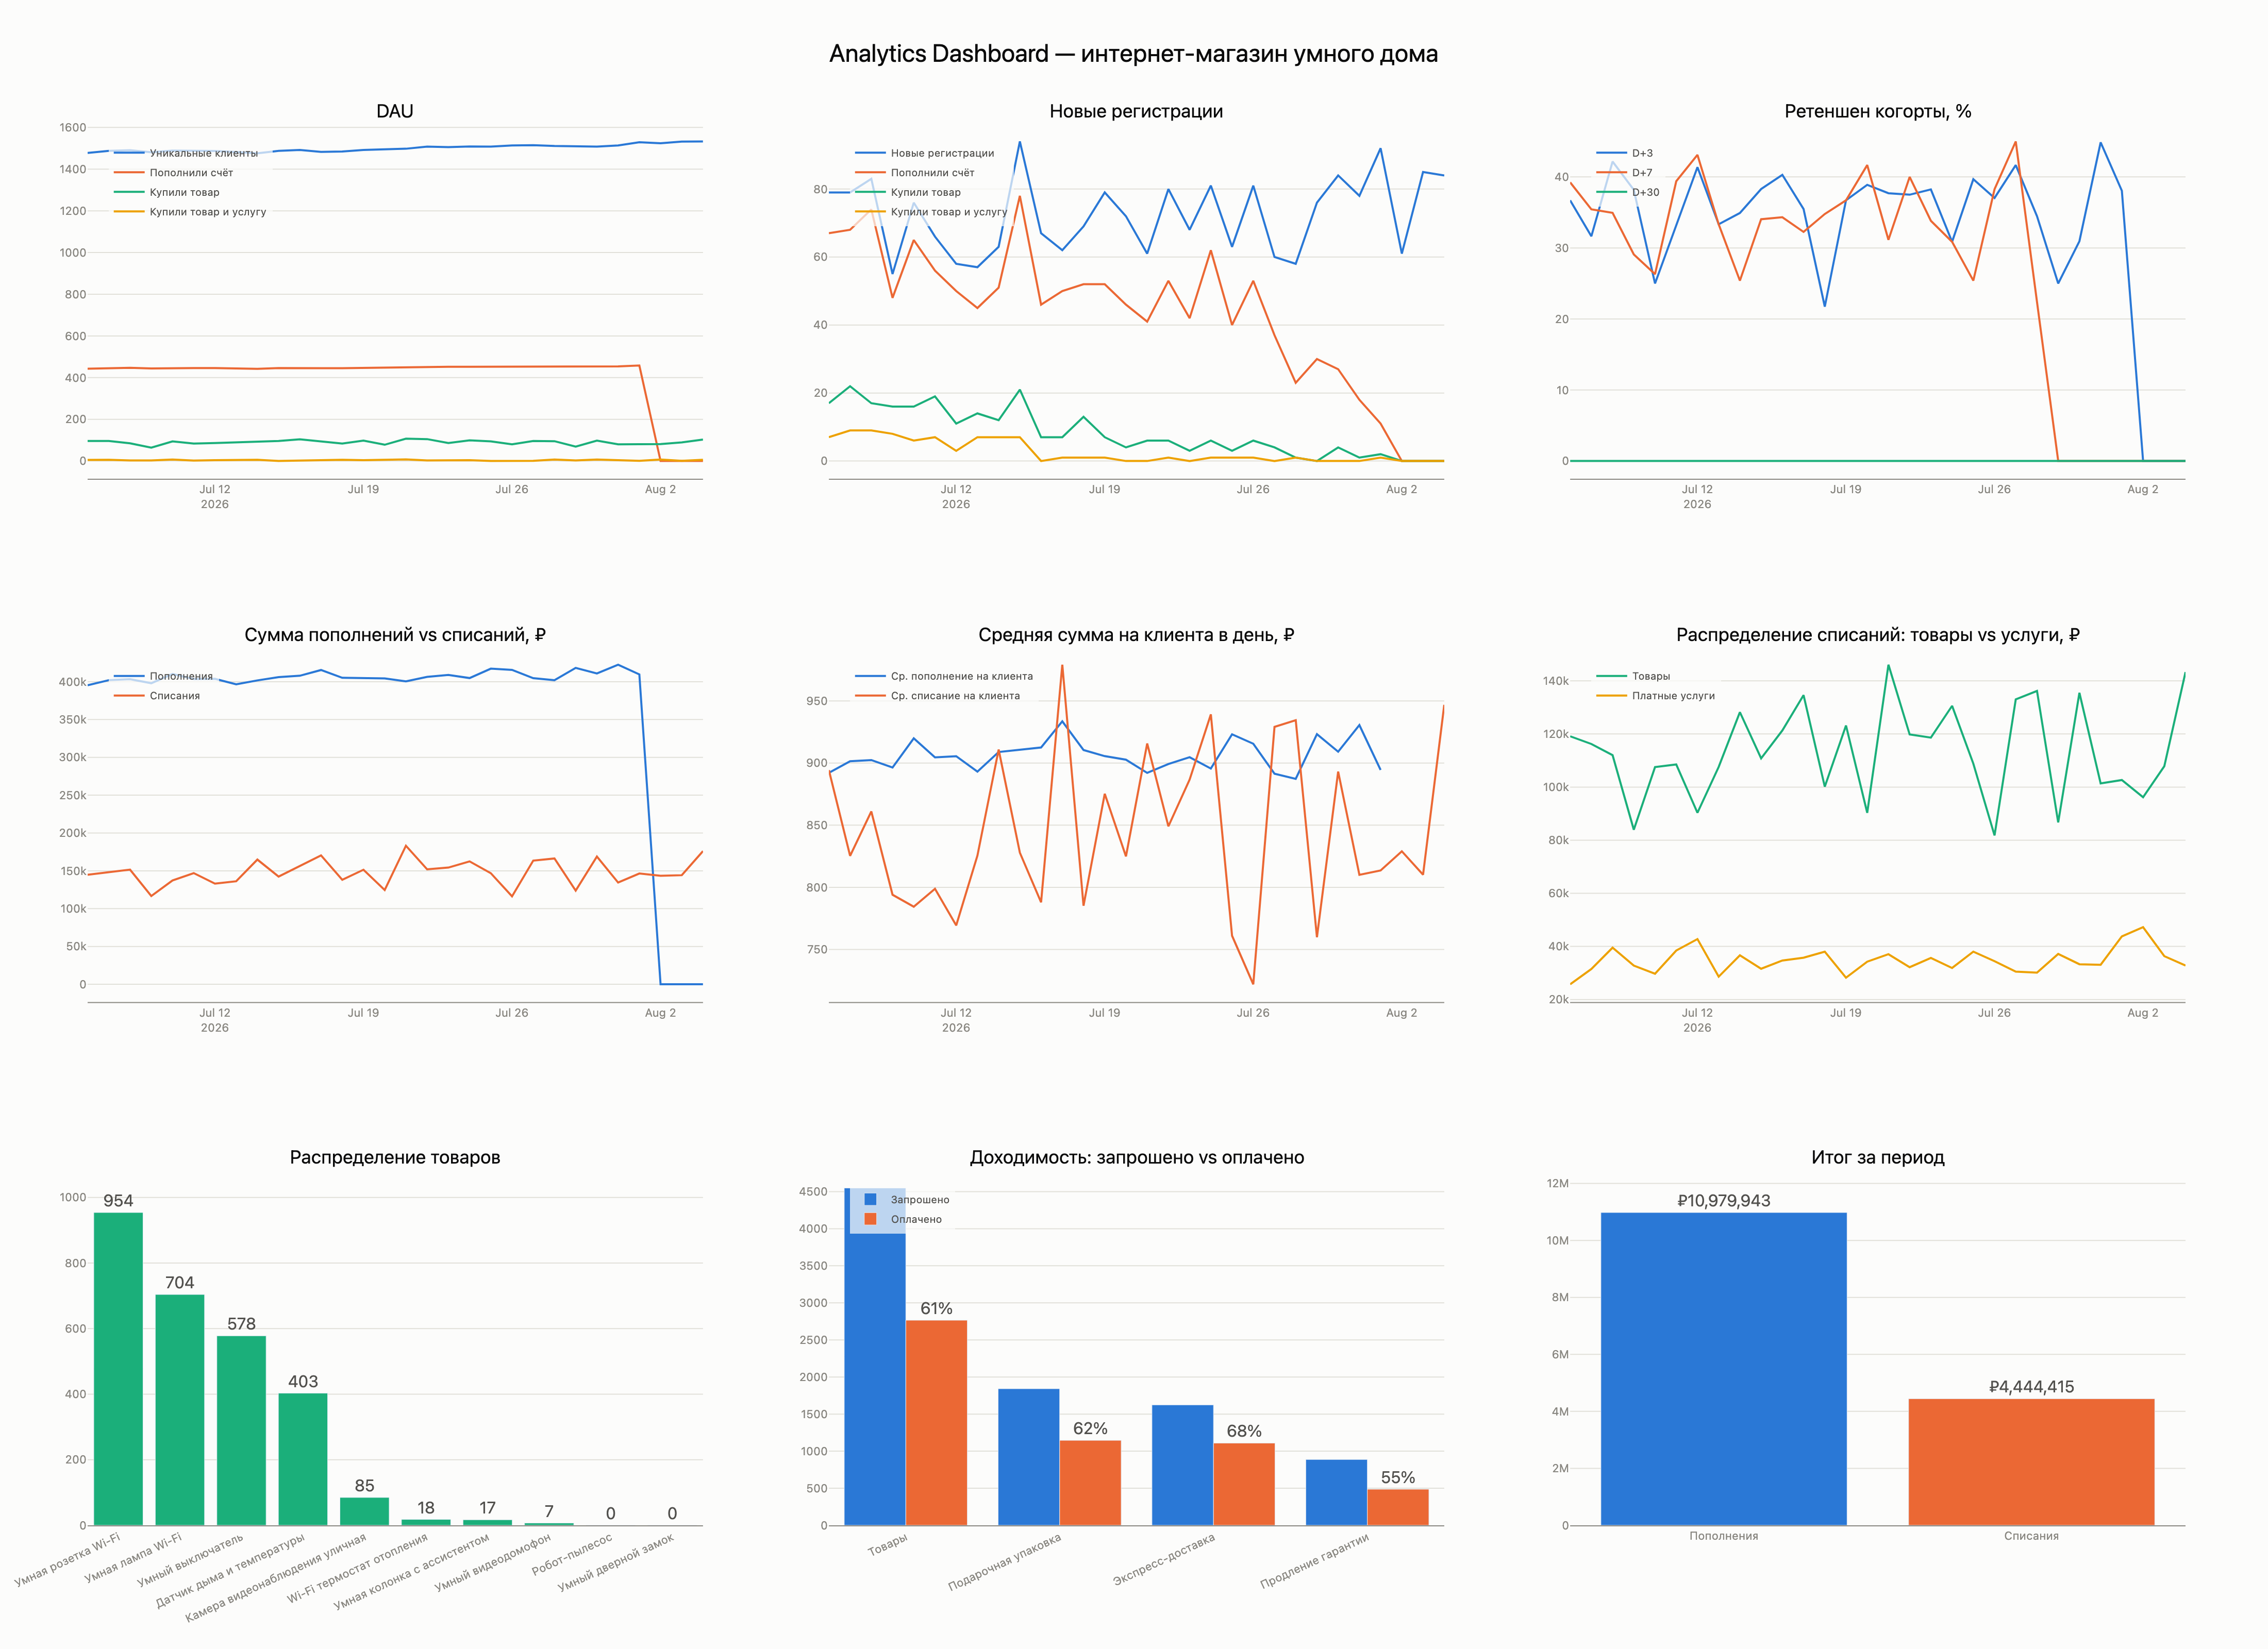

### После исправления

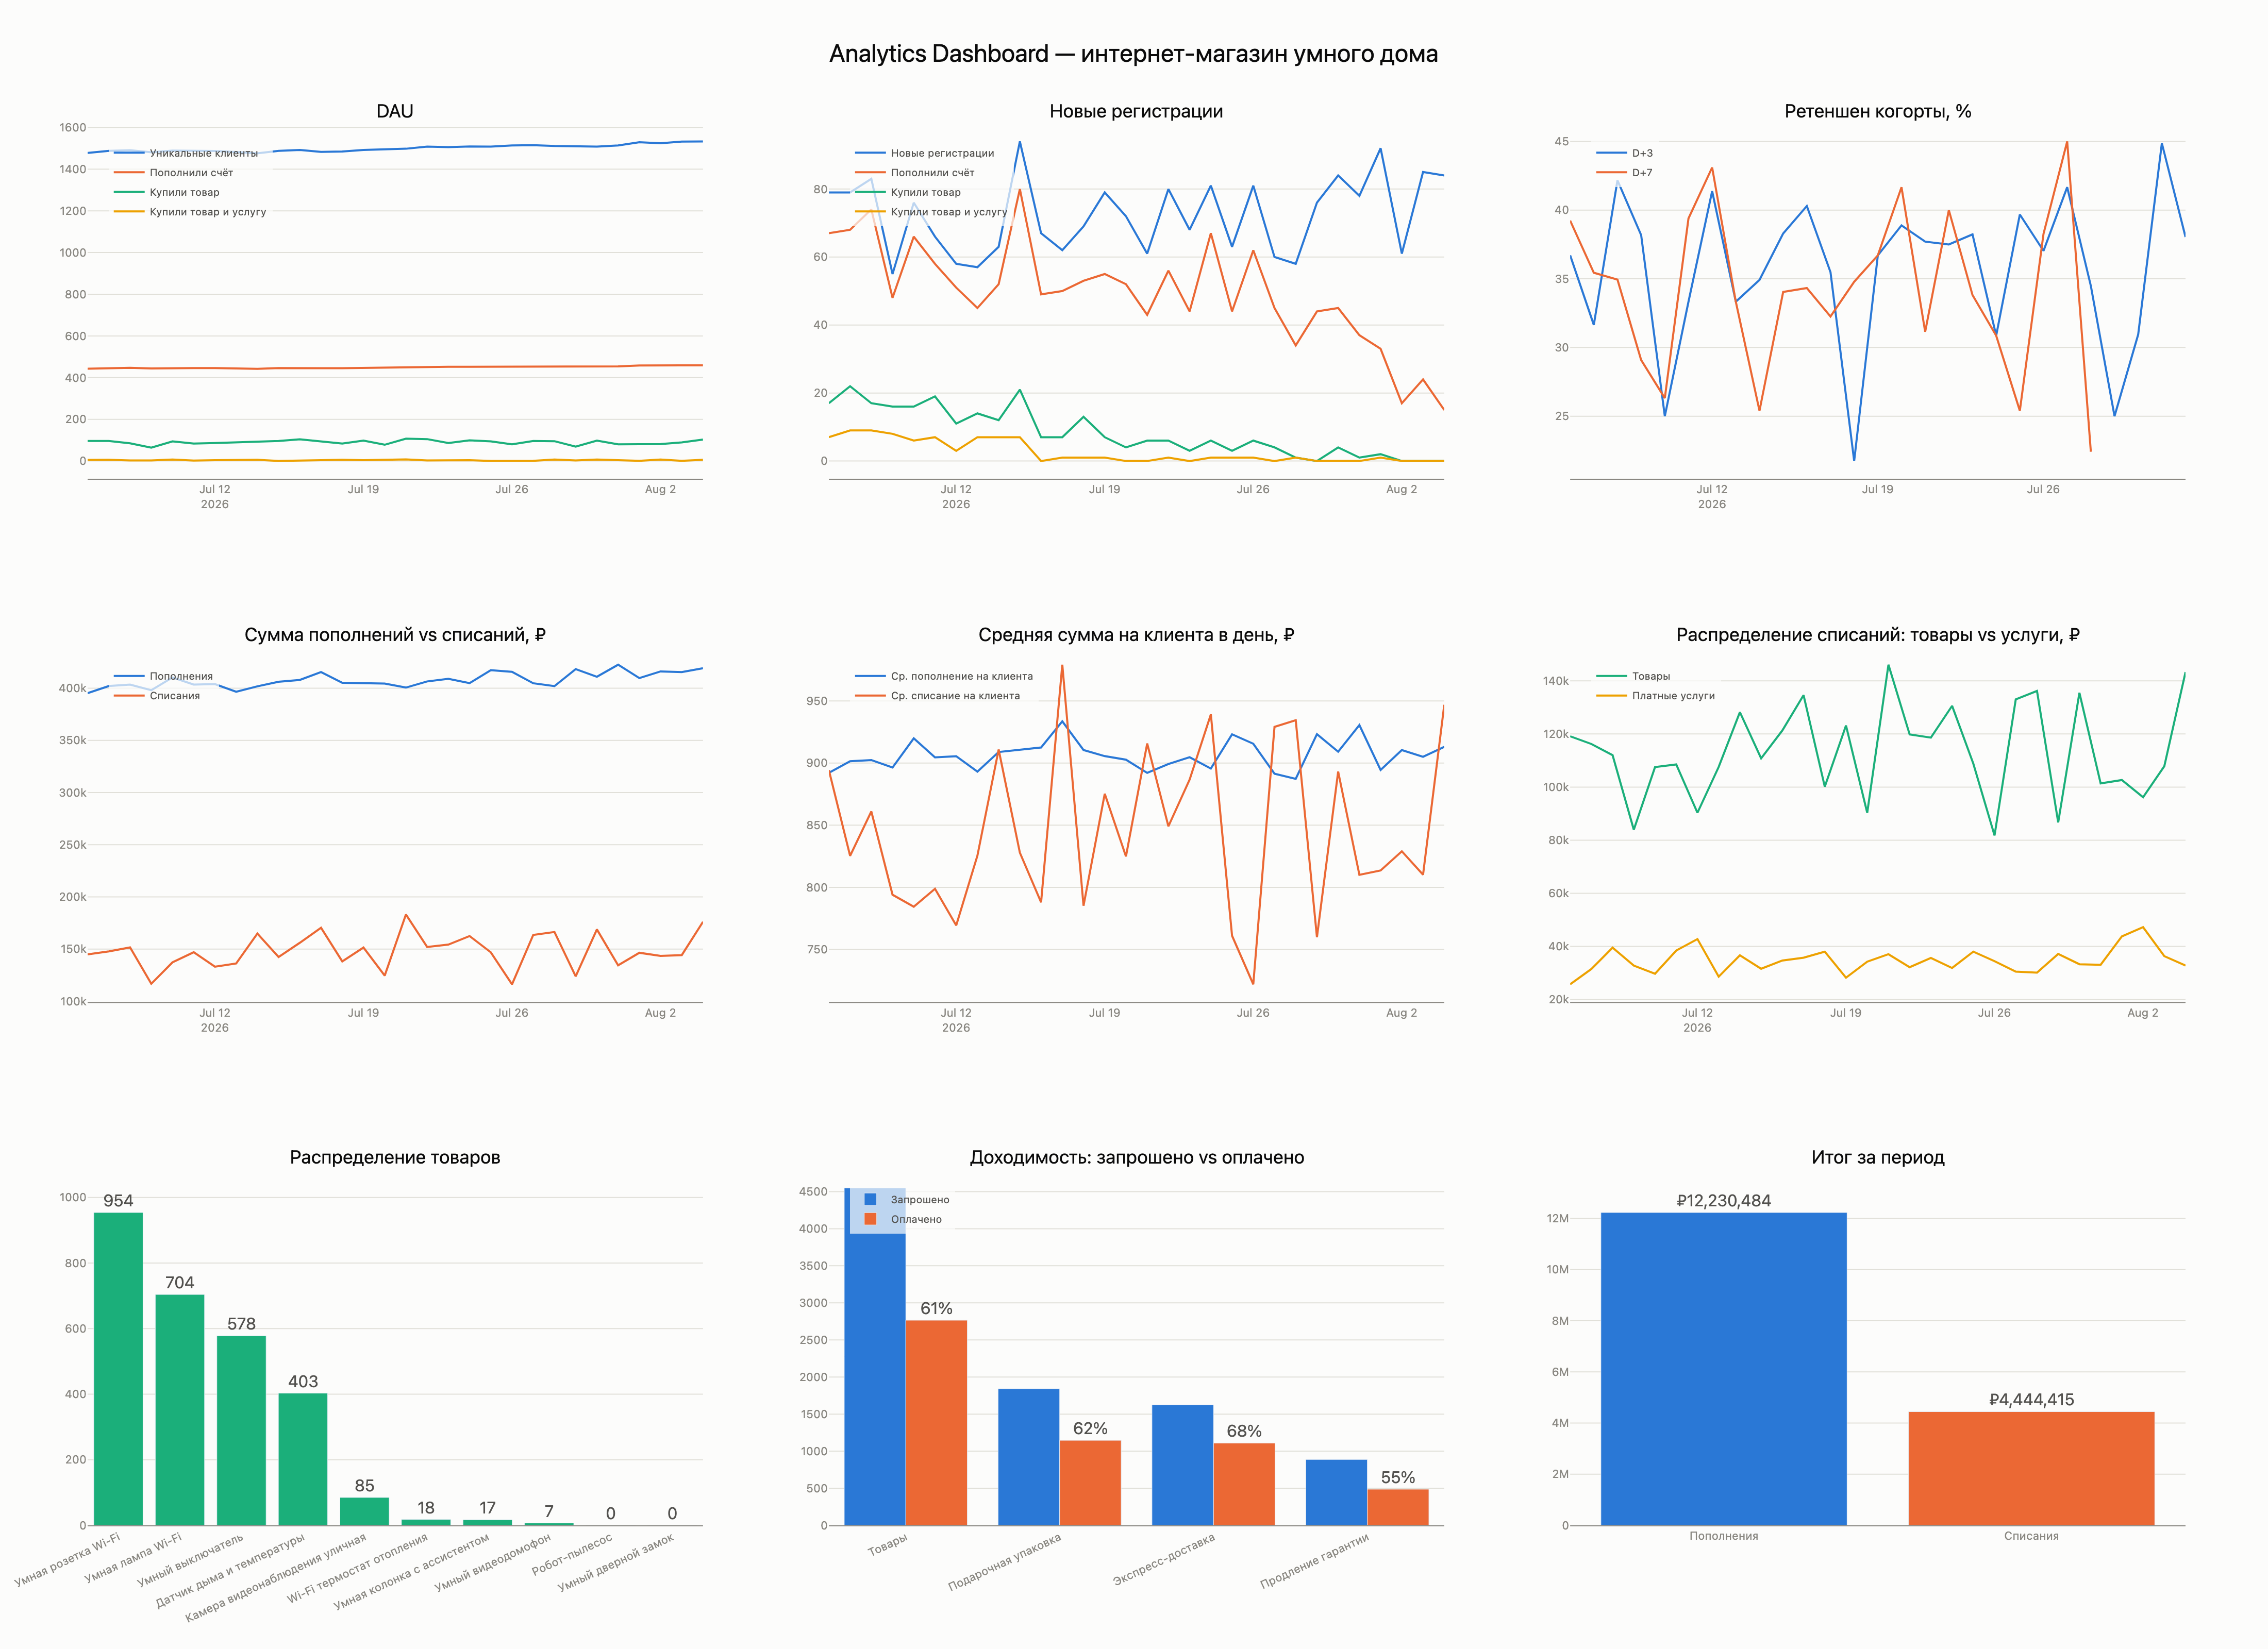

In [25]:
from IPython.display import Image, display, Markdown

display(Markdown("### До исправления"))
display(Image(filename=str(before_png), width=1400))

display(Markdown("### После исправления"))
display(Image(filename=str(after_png), width=1400))

**Что видно на сравнении:** в конце периода восстановились пополнения и число пользователей с пополнениями; Retention больше не должен показывать искусственный ноль для ещё не наблюдаемых когорт. Числовые изменения проверены в таблицах выше, а изображения помогают увидеть их на графиках.

## 7. Итоги

В работе нашла и проверила три проблемы:

1. **Пополнения:** после смены `topup` на `top-up` часть операций не попадала в витрины. После исправления учтены ещё **1 250 541 ₽** за 2–4 августа.
2. **Retention:** незавершённые когорты отображались как нулевое удержание. Теперь в расчёте и на графике используются пропуски.
3. **Фильтр тарифов:** пустой выбор показывал оба тарифа; теперь интерфейс просит выбрать хотя бы один.

Для проверки сравнивала сырые транзакции, исходные и пересчитанные витрины, а также графики до и после. Сырые данные не изменяла.

**Что закрепила:** SQL-запросы к SQLite, работа с pandas, проверка метрик, отладка Python-скриптов и визуальное сравнение результатов.

